# freMTPL2 — Pipeline : EDA → preprocessing → baseline → modèles

**Plan**
1. Setup, loadind
2. EDA (and diagnosis of the bloc)
3. Preprocessing (drop, cleaning, groups, split unique)
4. Evaluation tools
5. Baseline (Dummy + logistic)
6. Modeles : logistic regression + splines, decision tree, random forest, HistGradientBoosting, SVM, MLP
7. Leaderboard CV and test set (1 evaluation)

In [1]:
import time, warnings, pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, roc_auc_score, log_loss, brier_score_loss,
                             f1_score, precision_score, recall_score, precision_recall_curve)
from sklearn.model_selection import ParameterSampler, StratifiedGroupKFold, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, OneHotEncoder, OrdinalEncoder,
                                   SplineTransformer, StandardScaler)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})

SEED, N_JOBS = 42, 2
BLOCK_MAX_IDPOL = 24_500            # first IDpol block: every row has a claim

NUM = ["Exposure", "VehPower", "VehAge", "DrivAge", "BonusMalus", "Density"]
CAT = ["Area", "VehBrand", "VehGas", "Region"]
RAW = NUM + CAT
POLICYHOLDER_KEY = ["Area", "VehPower", "VehAge", "DrivAge", "BonusMalus",
                    "VehBrand", "VehGas", "Density", "Region"]
T0 = time.time()

In [2]:
# Raw files -> one row per policy (same as Step 1 of the previous notebook)
df_freq = pd.read_csv("freMTPL2freq.csv")
df_sev = pd.read_csv("freMTPL2sev.csv")

df_freq["IDpol"] = df_freq["IDpol"].astype(int)
df_sev["IDpol"] = df_sev["IDpol"].astype(int)
for col in df_freq.select_dtypes(exclude="number").columns:
    df_freq[col] = df_freq[col].astype(str).str.strip("'\"")

sev_agg = (df_sev.groupby("IDpol", as_index=False)
                 .agg(ClaimAmount=("ClaimAmount", "sum"), ClaimCountSev=("ClaimAmount", "count")))

df = df_freq.merge(sev_agg, on="IDpol", how="left")          # left merge keeps the file order
df["ClaimAmount"] = df["ClaimAmount"].fillna(0.0)
df["ClaimCountSev"] = df["ClaimCountSev"].fillna(0).astype(int)
df["HasClaim"] = (df["ClaimNb"] > 0).astype(int)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")

678,013 rows x 15 columns


## 2. EDA

### 2.1 General Info

In [3]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}\n")
display(df.dtypes.astype(str).to_frame("dtype").T)

print("=== Numeric ===")
display(df.describe().T)
print("=== Categorical ===")
display(df.select_dtypes(exclude="number").describe().T)

print("=== Missing values ===")
miss = pd.DataFrame({"missing": df.isna().sum(), "pct": (df.isna().mean() * 100).round(3)})
display(miss[miss.missing > 0] if (miss.missing > 0).any() else "No missing values")

print("=== Target (full data) ===")
print(df["HasClaim"].value_counts().rename("count").to_frame().assign(pct=lambda t: (t["count"] / len(df) * 100).round(3)))
print("\nClaimNb distribution:", df["ClaimNb"].value_counts().sort_index().to_dict())
print("Exposure > 1:", int((df["Exposure"] > 1).sum()), "| Exposure <= 0:", int((df["Exposure"] <= 0).sum()))

Rows: 678,013 | Columns: 15



,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,ClaimAmount,ClaimCountSev,HasClaim
dtype,int64,int64,float64,object,int64,int64,int64,int64,object,object,int64,object,float64,int64,int64


=== Numeric ===


,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.6219e+06,1.6418e+06,1.0000,1.1580e+06,2.2722e+06,4.0463e+06,6.1143e+06
ClaimNb,678013.0,5.3247e-02,2.4012e-01,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,1.6000e+01
Exposure,678013.0,5.2875e-01,3.6444e-01,0.0027,1.8000e-01,4.9000e-01,9.9000e-01,2.0100e+00
VehPower,678013.0,6.4546e+00,2.0509e+00,4.0000,5.0000e+00,6.0000e+00,7.0000e+00,1.5000e+01
VehAge,678013.0,7.0443e+00,5.6662e+00,0.0000,2.0000e+00,6.0000e+00,1.1000e+01,1.0000e+02
DrivAge,678013.0,4.5499e+01,1.4137e+01,18.0000,3.4000e+01,4.4000e+01,5.5000e+01,1.0000e+02
BonusMalus,678013.0,5.9762e+01,1.5637e+01,50.0000,5.0000e+01,5.0000e+01,6.4000e+01,2.3000e+02
Density,678013.0,1.7924e+03,3.9586e+03,1.0000,9.2000e+01,3.9300e+02,1.6580e+03,2.7000e+04
ClaimAmount,678013.0,6.0808e+01,5.7421e+03,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,4.0754e+06
ClaimCountSev,678013.0,3.9002e-02,2.0717e-01,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,1.6000e+01


=== Categorical ===


,count,unique,top,freq
Area,678013,6,C,191880
VehBrand,678013,11,B12,166024
VehGas,678013,2,Regular,345877
Region,678013,22,R24,160601


=== Missing values ===


'No missing values'

=== Target (full data) ===
           count     pct
HasClaim                
0         643953  94.976
1          34060   5.024

ClaimNb distribution: {0: 643953, 1: 32178, 2: 1784, 3: 82, 4: 7, 5: 2, 6: 1, 8: 1, 9: 1, 11: 3, 16: 1}
Exposure > 1: 1224 | Exposure <= 0: 0


### 2.2 Diagnosis of the claim bloc

Verifying the discovery : the 9139 first lines of the file only contain claims. The bloc is defined by `IDpol ≤ 24 500` (week 3). We also print the length of the sequence of claim by position to confirm the count.

In [4]:
df["is_block"] = df["IDpol"] <= BLOCK_MAX_IDPOL
n_block = int(df["is_block"].sum())

no_claim_pos = np.flatnonzero(df["HasClaim"].to_numpy() == 0)
run_len = int(no_claim_pos[0]) if len(no_claim_pos) else len(df)

print(f"Rows with IDpol <= {BLOCK_MAX_IDPOL:,}            : {n_block:,}")
print(f"  claim rate inside the block              : {df.loc[df.is_block, 'HasClaim'].mean():.1%}")
print(f"  claim rate outside the block             : {df.loc[~df.is_block, 'HasClaim'].mean():.2%}")
print(f"  block rows with no amount in severity file: {int((df.is_block & (df.ClaimCountSev == 0)).sum()):,}")
print(f"Consecutive claim rows at the top (position): {run_len:,}")
print(f"Last file position of a block row           : {int(np.flatnonzero(df.is_block.to_numpy()).max()):,}")
if n_block != run_len:
    print(f"\n-> Block size ({n_block:,}) differs from the initial run of claims ({run_len:,}): "
          "we drop by IDpol (the actual rule), not by position, so no row is missed.")

Rows with IDpol <= 24,500            : 9,139
  claim rate inside the block              : 100.0%
  claim rate outside the block             : 3.73%
  block rows with no amount in severity file: 8,851
Consecutive claim rows at the top (position): 9,387
Last file position of a block row           : 9,138

-> Block size (9,139) differs from the initial run of claims (9,387): we drop by IDpol (the actual rule), not by position, so no row is missed.


,other claims,first IDpol block
Exposure,0.7600,0.4600
VehAge,7.0000,2.0000
DrivAge,44.0000,49.0000
BonusMalus,55.0000,50.0000
Density,488.0000,322.0000
share Regular fuel,0.4883,0.6764
share BonusMalus = 50,0.4425,0.6695


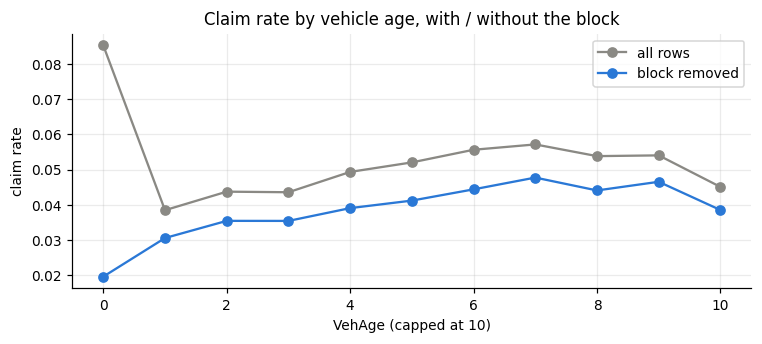

In [5]:
# How different is the block from the other claimants? (a model can exploit that)
claims = df[df.HasClaim == 1]
cmp = claims.groupby("is_block")[["Exposure", "VehAge", "DrivAge", "BonusMalus", "Density"]].median()
cmp["share Regular fuel"] = claims.groupby("is_block")["VehGas"].apply(lambda s: (s == "Regular").mean())
cmp["share BonusMalus = 50"] = claims.groupby("is_block")["BonusMalus"].apply(lambda s: (s == 50).mean())
cmp.index = ["other claims", "first IDpol block"]
display(cmp.T)

rate = (df.assign(VehAge_c=df.VehAge.clip(upper=10))
          .groupby("VehAge_c")
          .apply(lambda g: pd.Series({"all rows": g.HasClaim.mean(),
                                      "block removed": g.loc[~g.is_block, "HasClaim"].mean()}),
                 include_groups=False))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(rate.index, rate["all rows"], "o-", color="#8a8984", label="all rows")
ax.plot(rate.index, rate["block removed"], "o-", color="#2a78d6", label="block removed")
ax.set_xlabel("VehAge (capped at 10)"); ax.set_ylabel("claim rate"); ax.legend()
ax.set_title("Claim rate by vehicle age, with / without the block")
fig.tight_layout(); plt.show()

### 2.3 Distributions and frequence of claims (bloc excluded)

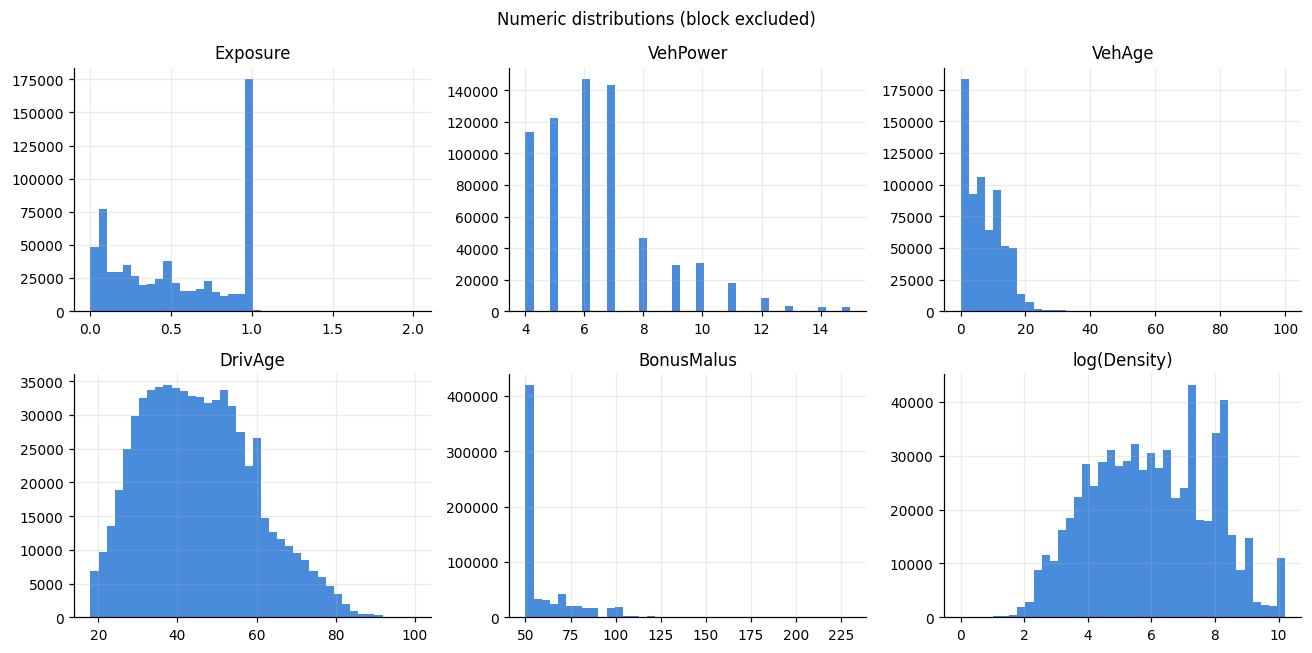

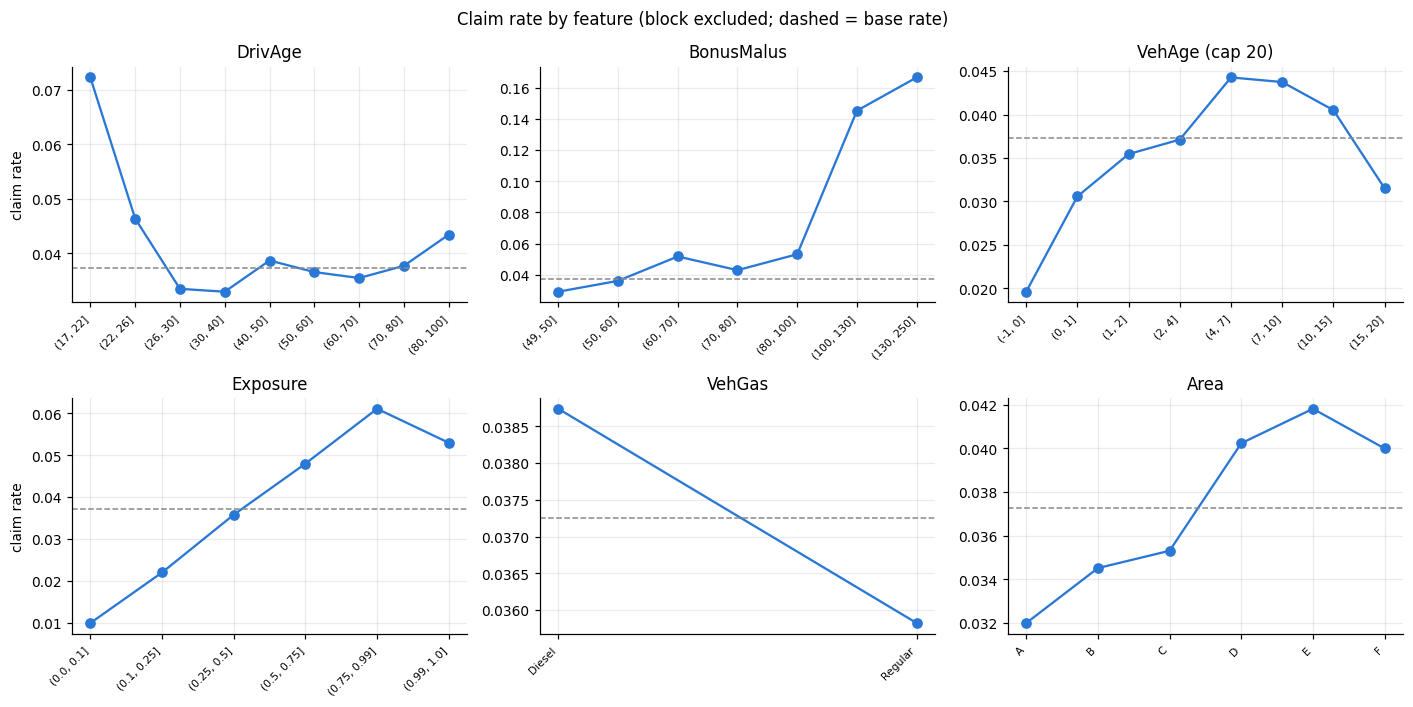

In [6]:
dfc = df.loc[~df["is_block"]]        # EDA on the data we will actually model

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), NUM):
    s = dfc[c]
    if c == "Density":
        s = np.log(s); c = "log(Density)"
    ax.hist(s, bins=40, color="#2a78d6", alpha=.85); ax.set_title(c)
fig.suptitle("Numeric distributions (block excluded)"); fig.tight_layout(); plt.show()

def rate_by(ax, s, title, bins=None):
    g = pd.cut(s, bins) if bins is not None else s
    r = dfc.groupby(g, observed=True)["HasClaim"].agg(["mean", "size"])
    r = r[r["size"] >= 200]
    ax.plot(range(len(r)), r["mean"], "o-", color="#2a78d6")
    ax.set_xticks(range(len(r))); ax.set_xticklabels([str(i) for i in r.index], rotation=45, ha="right", fontsize=7)
    ax.axhline(dfc.HasClaim.mean(), color="#8a8984", ls="--", lw=1); ax.set_title(title)

fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
rate_by(axes[0, 0], dfc["DrivAge"], "DrivAge", bins=[17, 22, 26, 30, 40, 50, 60, 70, 80, 100])
rate_by(axes[0, 1], dfc["BonusMalus"], "BonusMalus", bins=[49, 50, 60, 70, 80, 100, 130, 250])
rate_by(axes[0, 2], dfc["VehAge"].clip(upper=20), "VehAge (cap 20)", bins=[-1, 0, 1, 2, 4, 7, 10, 15, 20])
rate_by(axes[1, 0], dfc["Exposure"].clip(upper=1), "Exposure", bins=[0, .1, .25, .5, .75, .99, 1])
rate_by(axes[1, 1], dfc["VehGas"], "VehGas")
rate_by(axes[1, 2], dfc["Area"], "Area")
for ax in axes[:, 0]: ax.set_ylabel("claim rate")
fig.suptitle("Claim rate by feature (block excluded; dashed = base rate)"); fig.tight_layout(); plt.show()

Correlation with HasClaim:
Exposure      0.0880
BonusMalus    0.0653
logDensity    0.0185
VehAge        0.0118
DrivAge      -0.0060
VehPower      0.0008
Name: HasClaim, dtype: float64


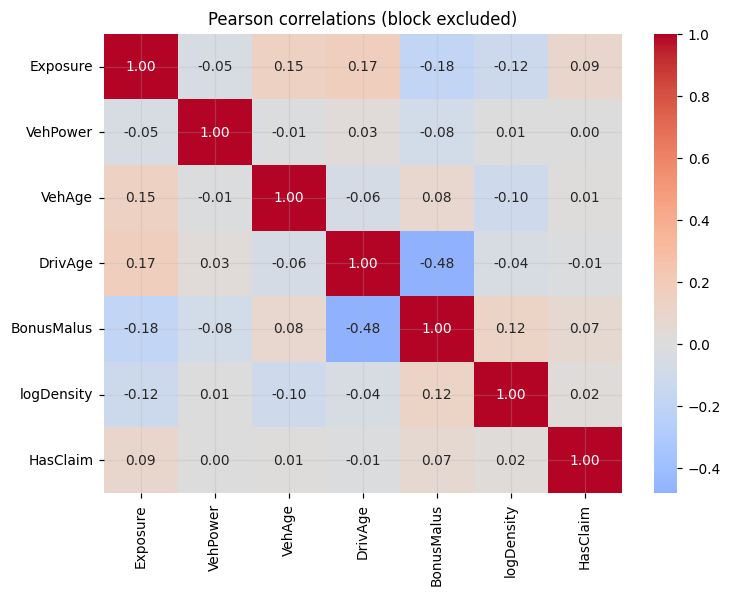

In [7]:
num_df = dfc[NUM + ["HasClaim"]].assign(Density=lambda t: np.log(t["Density"])).rename(columns={"Density": "logDensity"})
corr = num_df.corr()
print("Correlation with HasClaim:")
print(corr["HasClaim"].drop("HasClaim").sort_values(key=abs, ascending=False).round(4))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Pearson correlations (block excluded)"); fig.tight_layout(); plt.show()

## 3. Preprocessing

Order of operations (everything that depends on the data is before the split ; everythin that depends on the target is inside the pipeline on the train of each fold to prevent data leakage) :

1. **Drop of `IDpol ≤ 24 500`** — before the split, so absent from train, CV and test
2. Removeing expositions ≤ 0.
3. Id of insurance taker (`groups`) for a CV which doesn't split the lignes of a single person.
4. **One unique split** 80/20 by groups, then 5 folds of CV in train. The caps/log (fixed constants) are in the pipelines.

In [8]:
n_raw = len(df)
df_clean = df.loc[~df["is_block"]].copy()
n_after_block = len(df_clean)
df_clean = df_clean[df_clean["Exposure"] > 0].reset_index(drop=True)     # positional index from here on

print(f"raw rows                : {n_raw:,}  (positive rate {df['HasClaim'].mean():.4f})")
print(f"after block drop        : {n_after_block:,}  (-{n_raw - n_after_block:,})")
print(f"after Exposure > 0      : {len(df_clean):,}  (positive rate {df_clean['HasClaim'].mean():.4f})")
assert df_clean["IDpol"].min() > BLOCK_MAX_IDPOL, "block rows are still present"

# Policyholder id (same definition as the previous notebooks); computed on strings, before categorical cast
groups = df_clean.groupby(POLICYHOLDER_KEY, sort=False).ngroup()
print(f"{groups.nunique():,} policyholder groups for {len(df_clean):,} rows")

for c in CAT:                                      # category dtype (fixed lists, no target information)
    df_clean[c] = df_clean[c].astype("category")

X, y = df_clean[RAW], df_clean["HasClaim"]

raw rows                : 678,013  (positive rate 0.0502)
after block drop        : 668,874  (-9,139)
after Exposure > 0      : 668,874  (positive rate 0.0373)
521,925 policyholder groups for 668,874 rows


In [9]:
# One group-aware 80/20 split + 5 group-aware CV folds inside the train set.
# The cache file name includes the row count, so a cache built on the old (unfiltered) data is never reused.
SPLIT_CACHE = Path(f"splits_clean_{len(df_clean)}.pkl")
if SPLIT_CACHE.exists():
    tr_idx, te_idx, folds = pickle.loads(SPLIT_CACHE.read_bytes())
else:
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    tr_idx, te_idx = next(outer.split(X, y, groups))
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
    folds = list(inner.split(X.iloc[tr_idx], y.iloc[tr_idx], groups.iloc[tr_idx]))
    SPLIT_CACHE.write_bytes(pickle.dumps((tr_idx, te_idx, folds)))

Xtr, ytr = X.iloc[tr_idx].reset_index(drop=True), y.iloc[tr_idx].reset_index(drop=True)
Xte, yte = X.iloc[te_idx].reset_index(drop=True), y.iloc[te_idx].reset_index(drop=True)
gtr = groups.iloc[tr_idx].reset_index(drop=True)

assert not set(gtr) & set(groups.iloc[te_idx]), "a policyholder appears in both train and test"
print(f"train {len(Xtr):,} (pos {ytr.mean():.4f}) | test {len(Xte):,} (pos {yte.mean():.4f}) | {len(folds)} CV folds")

DATA = dict(X=Xtr, y=ytr, folds=folds, groups=gtr)

train 535,155 (pos 0.0373) | test 133,719 (pos 0.0372) | 5 CV folds


## 4. Evaluation metrics

* **Main metric : PR-AUC**, with the **lift** (PR-AUC ÷ Positiv Rate) to compare both versions.
* **F1** : not at 0,5. The threshold is chosen on the out-of-fold predictions and applied on the test set.
* Each model has a complete Pipeline recreated on each fold.

In [10]:
def cap_and_log(X):
    """Stateless caps / log with fixed constants (no leakage)."""
    X = X.copy()
    ops = {"Exposure": lambda s: np.log(s.clip(upper=1.0)), "VehAge": lambda s: s.clip(upper=20),
           "DrivAge": lambda s: s.clip(upper=90), "BonusMalus": lambda s: s.clip(upper=150),
           "Density": np.log}
    for c, f in ops.items():
        if c in X:
            X[c] = f(X[c])
    return X

cap = FunctionTransformer(cap_and_log, feature_names_out="one-to-one")
ohe = lambda: OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ordinal = lambda: ColumnTransformer(
    [("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT)],
    remainder="passthrough", verbose_feature_names_out=False)


def predict_score(m, X):
    """Probability if the model has one, otherwise the SVM decision function."""
    return m.predict_proba(X)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X)


def scores(y_true, s, proba=True):
    out = {"pr_auc": average_precision_score(y_true, s), "roc_auc": roc_auc_score(y_true, s)}
    out["log_loss"] = log_loss(y_true, np.clip(s, 1e-7, 1 - 1e-7)) if proba else np.nan
    out["brier"] = brier_score_loss(y_true, s) if proba else np.nan
    return out


def best_f1_threshold(y_true, s):
    prec, rec, thr = precision_recall_curve(y_true, s)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    i = np.nanargmax(f1[:-1])
    return thr[i], f1[i]


def run_cv(make_model, d, proba=True):
    """Group-aware CV. Returns (summary dict, out-of-fold scores)."""
    oof = np.zeros(len(d["y"])); rows = []; t = time.time()
    for a, b in d["folds"]:
        m = make_model().fit(d["X"].iloc[a], d["y"].iloc[a])
        oof[b] = predict_score(m, d["X"].iloc[b])
        rows.append(scores(d["y"].iloc[b], oof[b], proba))
    r = pd.DataFrame(rows)
    thr, f1 = best_f1_threshold(d["y"], oof)
    res = {**{k: r[k].mean() for k in r}, "pr_auc_sd": r.pr_auc.std(), "lift": r.pr_auc.mean() / d["y"].mean(),
           "F1@0.5": f1_score(d["y"], oof >= 0.5) if proba else np.nan,
           "best_thr": thr, "F1@best_thr": f1, "time_s": time.time() - t}
    return res, oof


MODELS, TRAIN, RESULTS, OOF = {}, {}, {}, {}

def evaluate(name, make_model, d=None, proba=True):
    """Run CV for one model and register it for the final leaderboard / test."""
    d = DATA if d is None else d
    MODELS[name], TRAIN[name] = make_model, d
    RESULTS[name], OOF[name] = run_cv(make_model, d, proba)
    r = RESULTS[name]
    print(f"{name:34s} PR-AUC {r['pr_auc']:.4f} ± {r['pr_auc_sd']:.4f} | lift x{r['lift']:.2f} | "
          f"ROC-AUC {r['roc_auc']:.4f} | F1@best_thr {r['F1@best_thr']:.3f} (thr {r['best_thr']:.3f}) | {r['time_s']:.0f}s")

## 5. Baseline

Two references : a `DummyClassifier` (Positive Rate → PR-AUC = Positive Rate, lift = 1) and the logistic regression, with caps/log and standardisation + one-hot.

In [11]:
evaluate("Dummy (prior)", lambda: DummyClassifier(strategy="prior"))

evaluate("Baseline LogReg", lambda: Pipeline([
    ("cap", cap),
    ("ct", ColumnTransformer([("num", StandardScaler(), NUM), ("cat", ohe(), CAT)])),
    ("clf", LogisticRegression(C=1.0, max_iter=1000)),
]))

Dummy (prior)                      PR-AUC 0.0373 ± 0.0006 | lift x1.00 | ROC-AUC 0.5000 | F1@best_thr 0.072 (thr 0.037) | 1s
Baseline LogReg                    PR-AUC 0.0925 ± 0.0015 | lift x2.48 | ROC-AUC 0.6892 | F1@best_thr 0.145 (thr 0.075) | 11s


## 6. Modèles

### 6.1 Logistic Regression + splines
Cubic splines on each numerical variable : the linear model can find non linear marginal effects (U from `DrivAge`, `VehAge = 0`), but no interactions.

In [12]:
evaluate("LogReg + splines", lambda: Pipeline([
    ("cap", cap),
    ("ct", ColumnTransformer([("num", SplineTransformer(n_knots=6, degree=3), NUM), ("cat", ohe(), CAT)])),
    ("clf", LogisticRegression(C=1.0, max_iter=2000)),
]))

LogReg + splines                   PR-AUC 0.0968 ± 0.0016 | lift x2.60 | ROC-AUC 0.6970 | F1@best_thr 0.156 (thr 0.076) | 20s


### 6.2 Decision Tree
Small random research on the depth and the minimal size of the leaves, scored by PR-AUC CV. The bigger leaves strongly regularize : the signal is weak and has noise.

In [13]:
def make_dt(**p):
    return lambda: Pipeline([("cap", cap), ("enc", ordinal()),
                             ("clf", DecisionTreeClassifier(random_state=SEED, **p))])

dt_space = {"max_depth": [4, 6, 8, 12], "min_samples_leaf": [50, 200, 500, 1000]}
dt_trials = []
for p in ParameterSampler(dt_space, n_iter=8, random_state=SEED):
    r, _ = run_cv(make_dt(**p), DATA)
    dt_trials.append({**p, "pr_auc": r["pr_auc"], "pr_auc_sd": r["pr_auc_sd"]})
dt_trials = pd.DataFrame(dt_trials).sort_values("pr_auc", ascending=False).reset_index(drop=True)
display(dt_trials.round(4))

dt_best = {k: int(dt_trials.loc[0, k]) for k in dt_space}
evaluate("DecisionTree", make_dt(**dt_best))

,min_samples_leaf,max_depth,pr_auc,pr_auc_sd
0,500,12,0.1015,0.0020
1,200,8,0.1004,0.0014
2,50,8,0.1000,0.0008
3,200,12,0.0997,0.0028
4,1000,8,0.0983,0.0019
5,200,6,0.0920,0.0012
6,50,4,0.0784,0.0005
7,200,4,0.0784,0.0005


DecisionTree                       PR-AUC 0.1015 ± 0.0020 | lift x2.72 | ROC-AUC 0.6867 | F1@best_thr 0.164 (thr 0.092) | 13s


### 6.3 Random Forest
Hyperparameters (100 trees, depth 8, `min_samples_leaf` 20, `max_features` 0,5).

In [14]:
evaluate("RandomForest", lambda: Pipeline([
    ("cap", cap), ("enc", ordinal()),
    ("clf", RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=20,
                                   max_features=0.5, n_jobs=N_JOBS, random_state=SEED)),
]))

RandomForest                       PR-AUC 0.1088 ± 0.0014 | lift x2.92 | ROC-AUC 0.7036 | F1@best_thr 0.172 (thr 0.080) | 196s


### 6.4 HistGradientBoosting
Native support of the categories, early stopping (10 % of each  fold). Hyperparameters by default from the `freMTPL2_week3_models.ipynb`. `TUNE_HGB = True` will relaunch a search of 10 configs.

In [15]:
TUNE_HGB = False
HGB_BEST = dict(learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=800, l2_regularization=10.0, max_features=1.0)

def make_hgb(**params):
    return lambda: Pipeline([("cap", cap), ("clf", HistGradientBoostingClassifier(
        categorical_features="from_dtype", max_iter=600, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=30, random_state=SEED, **params))])

if TUNE_HGB:
    space = {"learning_rate": [0.03, 0.05, 0.1], "max_leaf_nodes": [15, 31, 63],
             "min_samples_leaf": [50, 200, 800], "l2_regularization": [0.0, 1.0, 10.0],
             "max_features": [0.5, 0.8, 1.0]}
    trials = []
    for p in ParameterSampler(space, n_iter=10, random_state=SEED):
        r, _ = run_cv(make_hgb(**p), DATA)
        trials.append({**p, "pr_auc": r["pr_auc"], "pr_auc_sd": r["pr_auc_sd"]})
        print(f"PR-AUC {r['pr_auc']:.4f}  {p}")
    trials = pd.DataFrame(trials).sort_values("pr_auc", ascending=False).reset_index(drop=True)
    HGB_BEST = {k: trials.loc[0, k] for k in space}
    HGB_BEST["max_leaf_nodes"] = int(HGB_BEST["max_leaf_nodes"]); HGB_BEST["min_samples_leaf"] = int(HGB_BEST["min_samples_leaf"])
    display(trials.round(4))

print("HistGB params:", HGB_BEST)
evaluate("HistGradientBoosting", make_hgb(**HGB_BEST))

HistGB params: {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 800, 'l2_regularization': 10.0, 'max_features': 1.0}
HistGradientBoosting               PR-AUC 0.1174 ± 0.0020 | lift x3.15 | ROC-AUC 0.7117 | F1@best_thr 0.184 (thr 0.100) | 57s


### 6.5 SVM (noyau RBF)
A SVM is in O(n²) : too long on ~500k lines. We train it on a stratified subset (`SVM_N` lines) with its own grouped folds, then we evaluate on th ecomplete testset. We get a decision score (not probability) : log-loss / Brier aren't computed and the threshold F1 is the one of the decision score.

In [16]:
SVM_N = 15_000
sub = np.sort(train_test_split(np.arange(len(Xtr)), train_size=SVM_N, stratify=ytr, random_state=SEED)[0])
Xs, ys, gs = Xtr.iloc[sub].reset_index(drop=True), ytr.iloc[sub].reset_index(drop=True), gtr.iloc[sub].reset_index(drop=True)
DATA_SVM = dict(X=Xs, y=ys, groups=gs,
                folds=list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(Xs, ys, gs)))

evaluate("SVM (RBF, subsample)", lambda: Pipeline([
    ("cap", cap),
    ("ct", ColumnTransformer([("num", StandardScaler(), NUM), ("cat", ohe(), CAT)])),
    ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000)),
]), d=DATA_SVM, proba=False)

SVM (RBF, subsample)               PR-AUC 0.0602 ± 0.0071 | lift x1.62 | ROC-AUC 0.5844 | F1@best_thr 0.104 (thr -0.993) | 13s


### 6.6 MLP (neural network)
Midsize network (256-128-64) with early stopping. The input are standardized and the categories are one-hot encoded.

In [17]:
evaluate("MLP (256-128-64)", lambda: Pipeline([
    ("cap", cap),
    ("ct", ColumnTransformer([("num", StandardScaler(), NUM), ("cat", ohe(), CAT)])),
    ("clf", MLPClassifier(hidden_layer_sizes=(256, 128, 64), alpha=1e-3, batch_size=512,
                          max_iter=100, early_stopping=True, validation_fraction=0.1,
                          n_iter_no_change=10, random_state=SEED)),
]))

MLP (256-128-64)                   PR-AUC 0.1013 ± 0.0020 | lift x2.72 | ROC-AUC 0.6987 | F1@best_thr 0.163 (thr 0.084) | 413s


## 7. Results

### 7.1 Leaderboard CV (folds by groups, train only)

,pr_auc,pr_auc_sd,lift,roc_auc,log_loss,F1@0.5,best_thr,F1@best_thr,time_s
HistGradientBoosting,0.1174,0.0020,3.1502,0.7117,0.1466,0.0002,0.0995,0.1835,56.7796
RandomForest,0.1088,0.0014,2.9182,0.7036,0.1479,0.0009,0.0797,0.1719,196.2111
DecisionTree,0.1015,0.0020,2.7237,0.6867,0.1516,0.0000,0.0925,0.1643,12.6891
MLP (256-128-64),0.1013,0.0020,2.7176,0.6987,0.1496,0.0030,0.0840,0.1626,413.3031
LogReg + splines,0.0968,0.0016,2.5964,0.6970,0.1493,0.0001,0.0758,0.1559,19.6347
Baseline LogReg,0.0925,0.0015,2.4824,0.6892,0.1501,0.0007,0.0750,0.1451,11.3694
"SVM (RBF, subsample)",0.0602,0.0071,1.6154,0.5844,NaN,NaN,-0.9932,0.1037,12.6341
Dummy (prior),0.0373,0.0006,1.0000,0.5000,0.1592,0.0000,0.0371,0.0719,0.5794


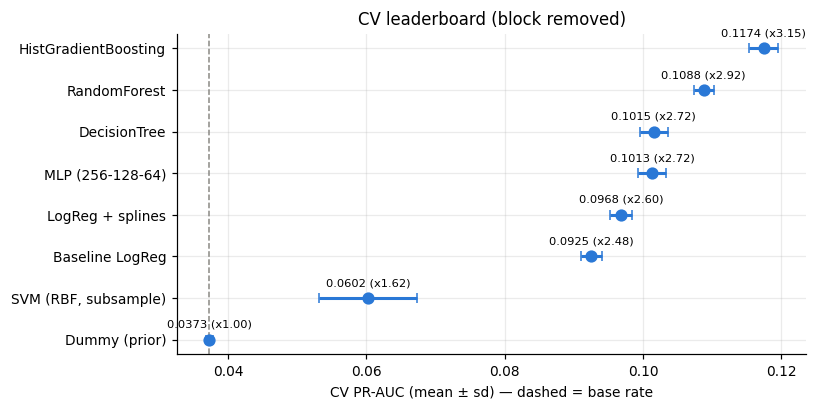

In [18]:
cols = ["pr_auc", "pr_auc_sd", "lift", "roc_auc", "log_loss", "F1@0.5", "best_thr", "F1@best_thr", "time_s"]
board = pd.DataFrame(RESULTS).T[cols].astype(float).sort_values("pr_auc", ascending=False)
display(board.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
v = board.iloc[::-1]
ax.errorbar(v.pr_auc, range(len(v)), xerr=v.pr_auc_sd, fmt="o", color="#2a78d6", ms=7, lw=2, capsize=3)
ax.axvline(DATA["y"].mean(), color="#8a8984", ls="--", lw=1)
for i, (p, l) in enumerate(zip(v.pr_auc, v.lift)):
    ax.annotate(f"{p:.4f} (x{l:.2f})", (p, i), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=7.5)
ax.set_yticks(range(len(v))); ax.set_yticklabels(v.index)
ax.set_xlabel("CV PR-AUC (mean ± sd) — dashed = base rate"); ax.set_title("CV leaderboard (block removed)")
fig.tight_layout(); plt.show()

### 7.2 Test set — evaluated once
Each model is retrained on trainset (SVM on its subset) and evaluated on the frozen testset. The threshold F1 comes from the CV (`best_thr`). Nothing is set on test.

In [19]:
test_rows = {}
for name, make in MODELS.items():
    d = TRAIN[name]
    m = make().fit(d["X"], d["y"])
    s = predict_score(m, Xte)
    proba = hasattr(m, "predict_proba")
    t = RESULTS[name]["best_thr"]
    sc = scores(yte, s, proba)
    test_rows[name] = {"pr_auc": sc["pr_auc"], "lift": sc["pr_auc"] / yte.mean(), "roc_auc": sc["roc_auc"],
                       "log_loss": sc["log_loss"], "CV threshold": t,
                       "F1@CV thr": f1_score(yte, s >= t), "precision@CV thr": precision_score(yte, s >= t, zero_division=0),
                       "recall@CV thr": recall_score(yte, s >= t), "CV pr_auc": RESULTS[name]["pr_auc"]}

test_board = pd.DataFrame(test_rows).T.astype(float).sort_values("pr_auc", ascending=False)
print(f"Test set: {len(yte):,} rows, positive rate {yte.mean():.4f} | total runtime {(time.time() - T0) / 60:.1f} min")
display(test_board.round(4))

Test set: 133,719 rows, positive rate 0.0372 | total runtime 31.3 min


,pr_auc,lift,roc_auc,log_loss,CV threshold,F1@CV thr,precision@CV thr,recall@CV thr,CV pr_auc
HistGradientBoosting,0.1200,3.2280,0.7144,0.1460,0.0995,0.1818,0.1683,0.1977,0.1174
RandomForest,0.1100,2.9589,0.7049,0.1476,0.0797,0.1753,0.1441,0.2239,0.1088
DecisionTree,0.1038,2.7926,0.6910,0.1508,0.0925,0.1730,0.1443,0.2160,0.1015
MLP (256-128-64),0.1000,2.6896,0.7028,0.1485,0.0840,0.1621,0.1241,0.2335,0.1013
LogReg + splines,0.0933,2.5091,0.6976,0.1492,0.0758,0.1552,0.1158,0.2349,0.0968
Baseline LogReg,0.0899,2.4179,0.6883,0.1501,0.0750,0.1410,0.1079,0.2033,0.0925
"SVM (RBF, subsample)",0.0565,1.5198,0.5924,NaN,-0.9932,0.0971,0.0692,0.1627,0.0602
Dummy (prior),0.0372,1.0000,0.5000,0.1589,0.0371,0.0717,0.0372,1.0000,0.0373
